
# NeuralBandit Paper Reproduction (GPU-Vectorized JAX)

This notebook is a reproduction of the paper:

**Allesiardo, Féraud, and Bouneffouf (2014), “A Neural Networks Committee for the Contextual Bandit Problem.”**

To reduce runtime:

1. **The 10 independent paper runs are executed simultaneously as a batch on the GPU.**
2. **The 15 committee models are represented as batched tensors and updated with the paper's backpropagation equations directly**, instead of invoking hundreds of millions of tiny Python/PyTorch `forward → backward → optimizer.step()` calls.

The notebook preserves the paper's stated setup:

- Forest Cover Type data.
- 94 binary context variables.
- 7 target classes used as actions.
- Dataset shuffled and played in a loop.
- Reward = 1 for the correct class, otherwise 0.
- One-hidden-layer sigmoid neural networks.
- Quadratic error.
- Fixed online learning step \(\lambda\).
- `gamma = 0.005`.
- `gamma_model = 0.1`.
- Hidden sizes `{1, 5, 25, 50, 100}`.
- Learning steps `{0.01, 0.1, 1}`.
- 15 NeuralBandit1 candidate models.
- NeuralBandit2 and NeuralBandit3.
- 10 runs beginning at random positions in the shuffled stream.
- Non-stationarity via circular class shift every 500,000 iterations.

### Source limitations that cannot be reconstructed exactly

The paper does not explicitly state the total horizon `T` in the experiment text. Figure 1 extends to approximately **2.5 million steps**, so this notebook uses `T = 2_500_000` and labels that value as figure-inferred.

The paper also says cumulative regret is computed relative to an **offline algorithm with 93% classification accuracy**, but does not identify that classifier or provide its per-observation predictions. Therefore, the exact Figure 1 regret sequence cannot be reconstructed from the paper alone. This notebook reports:

- an explicitly labeled **93%-rate reference regret approximation**, and
- **oracle cumulative regret**,

while using the paper's directly reported **last-100,000 classification accuracy** as the primary stationary reproduction target.

The paper reports stationary last-100k accuracy of approximately **76% for NeuralBandit2** and **73% for NeuralBandit3**.



## Why this version is faster

A previous attempt at reproducing the paper created 15 separate PyTorch models and performed an optimizer step for every model at every online observation. Across 2.5 million steps, 10 runs, and multiple conditions, that creates hundreds of millions of very small Python/PyTorch operations.

This version stores all 15 models in padded tensors. Models with fewer than 100 hidden neurons simply have their inactive hidden units masked out, so they remain mathematically equivalent to networks with hidden sizes 1, 5, 25, 50, or 100.

The 10 paper runs are an additional tensor dimension. JAX then compiles the entire sequential online-learning loop with `jax.lax.scan`, keeping it on the accelerator instead of returning to Python after every observation.


## 1. Imports and accelerator setup

In [ ]:

# ============================================================
# 1. Imports and accelerator setup
# ============================================================

import os
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import jax
import jax.numpy as jnp
from jax import lax
from jax import random as jr
from jax import nn as jnn

from sklearn.datasets import fetch_covtype
from sklearn.preprocessing import KBinsDiscretizer

# Use full float32 matmul precision where the accelerator supports
# lower-precision shortcuts (important when using A100-class GPUs).
jax.config.update("jax_default_matmul_precision", "highest")

print("JAX version:", jax.__version__)
print("Available devices:", jax.devices())

GPU_DEVICES = [d for d in jax.devices() if d.platform == "gpu"]

if GPU_DEVICES:
    print("Using GPU:", GPU_DEVICES[0])
else:
    print(
        "\nWARNING: JAX is not seeing a GPU. "
        "In Google Colab, select Runtime > Change runtime type > GPU, "
        "then restart and run this notebook from the top."
    )


JAX version: 0.11.1
Available devices: [CudaDevice(id=0)]
Using GPU: cuda:0


## 2. Paper constants and reproducibility settings

In [ ]:

# ============================================================
# 2. Paper constants and reproducibility settings
# ============================================================

DATA_SEED = 42
EXPERIMENT_SEED = 20261115

# Explicitly stated in the paper
GAMMA = np.float32(0.005)
GAMMA_MODEL = np.float32(0.1)

HIDDEN_SIZES = np.array(
    [1, 5, 25, 50, 100],
    dtype=np.int32
)

LEARNING_RATES = np.array(
    [0.01, 0.1, 1.0],
    dtype=np.float32
)

N_ACTIONS = 7
N_RUNS = 10
DRIFT_INTERVAL = 500_000
LAST_N = 100_000

# Figure-inferred: Figure 1 extends to about 2.5 million steps.
T = 2_500_000

# Stated paper reference accuracy; exact offline reward sequence is unavailable.
OFFLINE_REFERENCE_ACCURACY = np.float32(0.93)

# Results folder. In Colab, change this to a mounted Google Drive path
# if you want results to persist after the runtime disconnects.
if Path("/content").exists():
    RESULT_DIR = Path("/content/neural_bandit_jax_results")
else:
    RESULT_DIR = Path("./neural_bandit_jax_results")

RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("T:", f"{T:,}")
print("N_RUNS:", N_RUNS)
print("Results:", RESULT_DIR)


T: 2,500,000
N_RUNS: 10
Results: /content/neural_bandit_jax_results


## 3. Prepare the Forest Cover Type data exactly as described in the paper

In [ ]:

# ============================================================
# 3. Load and preprocess Forest Cover Type
# ============================================================

covtype = fetch_covtype(
    shuffle=False,
    as_frame=False
)

X_raw = covtype.data.astype(np.float32)
y_raw = covtype.target.astype(np.int32)

print("Raw X:", X_raw.shape)
print("Raw y:", y_raw.shape)
print("Classes:", np.unique(y_raw))

# Raw data:
# first 10 columns = quantitative
# remaining 44 = already-binary wilderness/soil indicators
X_continuous = X_raw[:, :10]
X_binary = X_raw[:, 10:]

# Paper: each continuous variable is recoded by equal frequency
# into five binary variables.
binner = KBinsDiscretizer(
    n_bins=5,
    encode="ordinal",
    strategy="quantile",
    subsample=None,
    dtype=np.float32
)

X_binned = binner.fit_transform(
    X_continuous
).astype(np.int32)

assert np.all(binner.n_bins_ == 5)

n_samples = len(y_raw)

# 10 continuous * 5 binary bins = 50
# + 44 existing binary indicators = 94
X = np.zeros(
    (n_samples, 94),
    dtype=np.float32
)

rows = np.arange(n_samples)

for feature_idx in range(10):
    start = feature_idx * 5
    X[
        rows,
        start + X_binned[:, feature_idx]
    ] = 1.0

X[:, 50:] = X_binary

# Labels 1..7 -> internal actions 0..6.
y = y_raw - 1

assert X.shape == (581012, 94)
assert set(np.unique(X)).issubset({0.0, 1.0})
assert y.min() == 0
assert y.max() == 6

print("Paper-style X:", X.shape)
print("Actions:", len(np.unique(y)))


Raw X: (581012, 54)
Raw y: (581012,)
Classes: [1 2 3 4 5 6 7]
Paper-style X: (581012, 94)
Actions: 7


In [ ]:

# ============================================================
# 4. Create the shuffled looping stream and 10 random starts
# ============================================================

data_rng = np.random.default_rng(DATA_SEED)

# Paper: dataset is shuffled.
data_order = data_rng.permutation(
    len(y)
).astype(np.int32)

# Paper: each run begins at a random position in the data.
experiment_rng = np.random.default_rng(
    EXPERIMENT_SEED
)

RUN_STARTS = experiment_rng.integers(
    0,
    len(y),
    size=N_RUNS,
    dtype=np.int32
)

RUN_SEEDS = experiment_rng.integers(
    1,
    2_000_000_000,
    size=N_RUNS,
    dtype=np.int64
)

print("Random starts:", RUN_STARTS)
print("Run seeds:", RUN_SEEDS)


Random starts: [262173 291602  81021 186783 482562 340987 473909 174264 181092 405233]
Run seeds: [ 240230488  778896481  707787953 1105477369   19569818 1936129619
  968589200  635380296 1955263105 1207452093]



## 5. Vectorized representation of the paper's 15 models

The candidate list is the Cartesian product:

$$
C \in \{1,5,25,50,100\},
\qquad
\lambda \in \{0.01,0.1,1\}.
$$

That gives 15 NeuralBandit1 models.

For GPU efficiency, every model is stored in a tensor with a maximum hidden size of 100. A binary mask ensures that a model with, for example, 5 hidden neurons uses exactly its first 5 units; the other 95 units have zero weights and are never updated.

The paper's connection count is $N=\dim(X)C+C$, which corresponds to:

- input-to-hidden weights: $94 \times C$
- hidden-to-output weights: $C$

with no bias terms. That is the architecture implemented below.


In [ ]:

# ============================================================
# 5. Model-grid tensors
# ============================================================

MODEL_HIDDEN = np.repeat(
    HIDDEN_SIZES,
    len(LEARNING_RATES)
).astype(np.int32)

MODEL_LR = np.tile(
    LEARNING_RATES,
    len(HIDDEN_SIZES)
).astype(np.float32)

N_MODELS = len(MODEL_HIDDEN)
MAX_HIDDEN = int(HIDDEN_SIZES.max())
INPUT_DIM = X.shape[1]

model_table = pd.DataFrame({
    "model_idx": np.arange(N_MODELS),
    "hidden_dim": MODEL_HIDDEN,
    "learning_rate": MODEL_LR
})

display(model_table)

# Active-unit mask, shape [M, Hmax].
HIDDEN_MASK_NP = (
    np.arange(MAX_HIDDEN)[None, :]
    < MODEL_HIDDEN[:, None]
).astype(np.float32)

assert N_MODELS == 15


,model_idx,hidden_dim,learning_rate
0,0,1,0.01
1,1,1,0.10
2,2,1,1.00
3,3,5,0.01
4,4,5,0.10
5,5,5,1.00
6,6,25,0.01
7,7,25,0.10
8,8,25,1.00
9,9,50,0.01


In [ ]:

# ============================================================
# 6. Move immutable data/constants to JAX device
# ============================================================

X_J = jax.device_put(
    jnp.asarray(X, dtype=jnp.float32)
)

Y_J = jax.device_put(
    jnp.asarray(y, dtype=jnp.int32)
)

ORDER_J = jax.device_put(
    jnp.asarray(data_order, dtype=jnp.int32)
)

STARTS_J = jax.device_put(
    jnp.asarray(RUN_STARTS, dtype=jnp.int32)
)

MODEL_LR_J = jax.device_put(
    jnp.asarray(MODEL_LR, dtype=jnp.float32)
)

HIDDEN_MASK_J = jax.device_put(
    jnp.asarray(HIDDEN_MASK_NP, dtype=jnp.float32)
)

RUN_IDX = jnp.arange(
    N_RUNS,
    dtype=jnp.int32
)

MODEL_IDX = jnp.arange(
    N_MODELS,
    dtype=jnp.int32
)

ACTION_IDX = jnp.arange(
    N_ACTIONS,
    dtype=jnp.int32
)

# One independent PRNG stream per paper run.
RUN_KEYS = jnp.stack([
    jr.PRNGKey(int(seed))
    for seed in RUN_SEEDS
])

print("X device:", X_J.device)


X device: cuda:0



## 7. Direct implementation of the paper's neural-network update

For a played action, the network output is

$$
o=\sigma\left(\sum_j v_j h_j\right),
\qquad
h_j=\sigma\left(\sum_i w_{ji}x_i\right).
$$

With quadratic error and inverse-probability weighting, plain gradient descent gives

$$
\delta_o =
\frac{(y-o)o(1-o)}{P_t(k)}.
$$

The hidden-to-output update is

$$
v_j \leftarrow v_j + \lambda\,\delta_o h_j,
$$

and the input-to-hidden update is

$$
w_{ji} \leftarrow
w_{ji}+
\lambda\,
h_j(1-h_j)v_j\delta_o x_i.
$$

This is algebraically the same SGD update produced by backpropagation on

$$
\frac{1}{2}\frac{(o-y)^2}{P_t(k)},
$$

but avoids building an autograd graph and calling an optimizer separately for every tiny network.


In [ ]:

# ============================================================
# 7. JAX helpers
# ============================================================

def _init_one_run(key):
    """Initialize all 15 models for one paper run."""
    key_w1, key_w2, key_rng = jr.split(
        key,
        3
    )

    # Shape:
    # W1 [M, K, Hmax, D]
    # W2 [M, K, Hmax]
    w1 = jr.uniform(
        key_w1,
        shape=(
            N_MODELS,
            N_ACTIONS,
            MAX_HIDDEN,
            INPUT_DIM
        ),
        minval=-0.5,
        maxval=0.5,
        dtype=jnp.float32
    )

    w2 = jr.uniform(
        key_w2,
        shape=(
            N_MODELS,
            N_ACTIONS,
            MAX_HIDDEN
        ),
        minval=-0.5,
        maxval=0.5,
        dtype=jnp.float32
    )

    # Inactive padded hidden units are exactly zero
    # and remain zero throughout training.
    w1 = (
        w1
        * HIDDEN_MASK_J[:, None, :, None]
    )

    w2 = (
        w2
        * HIDDEN_MASK_J[:, None, :]
    )

    return w1, w2, key_rng


def _init_all_runs(run_keys):
    """
    Batch the 10 independent paper runs:
    W1 [R, M, K, Hmax, D]
    W2 [R, M, K, Hmax]
    """
    return jax.vmap(
        _init_one_run
    )(run_keys)


def _split_run_keys(keys, n):
    """
    Split each run's PRNG key independently.
    """
    splits = jax.vmap(
        lambda k: jr.split(k, n)
    )(keys)

    new_keys = splits[:, 0]

    extra_keys = tuple(
        splits[:, i]
        for i in range(1, n)
    )

    return new_keys, extra_keys


def _sample_categorical(keys, probabilities):
    """
    Sample independently for each run.

    probabilities may be:
      [R, choices]
    or
      [R, K, choices]

    In the second case, one draw is produced for
    every action-specific EXP3 distribution.
    """
    return jax.vmap(
        lambda key, p:
            jr.categorical(
                key,
                jnp.log(p),
                axis=-1
            )
    )(
        keys,
        probabilities
    ).astype(jnp.int32)


def _exp3_probabilities(log_weights):
    """
    Equation (2), using log-weights for numerical stability.
    """
    normalized = jnn.softmax(
        log_weights,
        axis=-1
    )

    return (
        (1.0 - GAMMA_MODEL)
        * normalized
        + GAMMA_MODEL / N_MODELS
    )


def _update_played_action_all_models(
    w1,
    w2,
    contexts,
    chosen_actions,
    rewards,
    behavior_action_probability
):
    """
    Update the neural network corresponding to the
    played action in every one of the 15 models.

    This is Algorithm 2 / 3's parallel model update,
    vectorized across:
      - 10 runs
      - 15 candidate models
      - hidden units
      - input features
    """

    # Gather the played-action network from all models.
    # Shapes:
    # played_w1 [R, M, Hmax, D]
    # played_w2 [R, M, Hmax]
    played_w1 = w1[
        RUN_IDX[:, None],
        MODEL_IDX[None, :],
        chosen_actions[:, None]
    ]

    played_w2 = w2[
        RUN_IDX[:, None],
        MODEL_IDX[None, :],
        chosen_actions[:, None]
    ]

    # Forward pass for the played action in every model.
    hidden = jnn.sigmoid(
        jnp.einsum(
            "rmhd,rd->rmh",
            played_w1,
            contexts
        )
    )

    output = jnn.sigmoid(
        jnp.sum(
            hidden * played_w2,
            axis=-1
        )
    )

    # SGD/backprop delta for quadratic error.
    delta_out = (
        (rewards[:, None] - output)
        * output
        * (1.0 - output)
        / behavior_action_probability[:, None]
    )

    # Hidden-to-output update.
    new_played_w2 = (
        played_w2
        + MODEL_LR_J[None, :, None]
        * delta_out[:, :, None]
        * hidden
        * HIDDEN_MASK_J[None, :, :]
    )

    # IMPORTANT: hidden delta uses the OLD output weights,
    # exactly as ordinary backpropagation/autograd does.
    delta_hidden = (
        hidden
        * (1.0 - hidden)
        * played_w2
        * delta_out[:, :, None]
    )

    # Input-to-hidden update.
    new_played_w1 = (
        played_w1
        + MODEL_LR_J[
            None, :, None, None
        ]
        * delta_hidden[:, :, :, None]
        * contexts[:, None, None, :]
        * HIDDEN_MASK_J[
            None, :, :, None
        ]
    )

    # Scatter the updated played-action networks back.
    w1 = w1.at[
        RUN_IDX[:, None],
        MODEL_IDX[None, :],
        chosen_actions[:, None]
    ].set(new_played_w1)

    w2 = w2.at[
        RUN_IDX[:, None],
        MODEL_IDX[None, :],
        chosen_actions[:, None]
    ].set(new_played_w2)

    return w1, w2



## 8. NeuralBandit2 — compiled 10-run implementation

The paper's Algorithm 2 does the following at each time step:

1. EXP3 chooses one NeuralBandit1 model.
2. That selected model chooses the played action.
3. The reward for that action is observed.
4. The network corresponding to the played action is updated in **every model**.
5. EXP3 updates the selected model's weight.

Equation (1) requires the probability of the observed action. Algorithm 2 only has one behavior policy actually sample that action: the selected NeuralBandit1 model. This implementation therefore uses that **actual behavior-policy probability** in the inverse-probability update for all candidate models. The paper does not separately define an alternative sampling probability for the unselected models.


In [ ]:

# ============================================================
# 8. NeuralBandit2
# ============================================================

def _nb2_step(
    carry,
    t,
    starts,
    x_data,
    y_data,
    order,
    nonstationary
):
    (
        w1,
        w2,
        exp3_log_weights,
        rng_keys,
        last100k_correct
    ) = carry

    # --------------------------------------------------------
    # Current context for each of the 10 runs
    # --------------------------------------------------------
    positions = (
        starts + t
    ) % y_data.shape[0]

    row_idx = order[positions]

    contexts = x_data[row_idx]
    base_actions = y_data[row_idx]

    # Paper non-stationarity:
    # 1->2, 2->3, ..., 7->1 every 500,000 rounds.
    shift = jnp.where(
        nonstationary,
        (t // DRIFT_INTERVAL) % N_ACTIONS,
        0
    )

    true_actions = (
        base_actions + shift
    ) % N_ACTIONS

    # --------------------------------------------------------
    # EXP3 model selection — Equation (2)
    # --------------------------------------------------------
    model_probabilities = (
        _exp3_probabilities(
            exp3_log_weights
        )
    )

    rng_keys, split_keys = (
        _split_run_keys(
            rng_keys,
            3
        )
    )

    model_keys, action_keys = (
        split_keys
    )

    chosen_models = _sample_categorical(
        model_keys,
        model_probabilities
    )

    # --------------------------------------------------------
    # Selected NeuralBandit1 scores all seven actions
    # --------------------------------------------------------
    selected_w1 = w1[
        RUN_IDX,
        chosen_models
    ]

    selected_w2 = w2[
        RUN_IDX,
        chosen_models
    ]

    # selected_w1 [R,K,H,D]
    hidden = jnn.sigmoid(
        jnp.einsum(
            "rkhd,rd->rkh",
            selected_w1,
            contexts
        )
    )

    scores = jnn.sigmoid(
        jnp.sum(
            hidden * selected_w2,
            axis=-1
        )
    )

    greedy_actions = jnp.argmax(
        scores,
        axis=-1
    ).astype(jnp.int32)

    # --------------------------------------------------------
    # NeuralBandit1 action distribution
    # P_t(k) = (1-gamma) I[k=greedy] + gamma/K
    # --------------------------------------------------------
    action_probabilities = jnp.full(
        (N_RUNS, N_ACTIONS),
        GAMMA / N_ACTIONS,
        dtype=jnp.float32
    )

    action_probabilities = (
        action_probabilities
        .at[
            RUN_IDX,
            greedy_actions
        ]
        .add(1.0 - GAMMA)
    )

    chosen_actions = _sample_categorical(
        action_keys,
        action_probabilities
    )

    behavior_probability = (
        action_probabilities[
            RUN_IDX,
            chosen_actions
        ]
    )

    rewards = (
        chosen_actions
        == true_actions
    ).astype(jnp.float32)

    # --------------------------------------------------------
    # Algorithm 2:
    # update played-action network in every model
    # --------------------------------------------------------
    w1, w2 = (
        _update_played_action_all_models(
            w1=w1,
            w2=w2,
            contexts=contexts,
            chosen_actions=chosen_actions,
            rewards=rewards,
            behavior_action_probability=
                behavior_probability
        )
    )



    # --------------------------------------------------------
    # EXP3 update — Equation (3)
    # --------------------------------------------------------
    chosen_model_probability = (
        model_probabilities[
            RUN_IDX,
            chosen_models
        ]
    )

    exp3_increment = (
        GAMMA_MODEL
        * rewards
        / (
            chosen_model_probability
            * N_MODELS
        )
    )

    exp3_log_weights = (
        exp3_log_weights
        .at[
            RUN_IDX,
            chosen_models
        ]
        .add(exp3_increment)
    )

    # Paper reports accuracy over final 100,000 predictions.
    last100k_correct = (
        last100k_correct
        + jnp.where(
            t >= T - LAST_N,
            rewards,
            0.0
        )
    )

    new_carry = (
        w1,
        w2,
        exp3_log_weights,
        rng_keys,
        last100k_correct
    )

    # Only retain mean reward at each time step.
    # This is enough to construct the 10-run averaged curves.
    return new_carry, rewards.mean()


def _run_nb2(
    run_keys,
    starts,
    x_data,
    y_data,
    order,
    nonstationary
):
    w1, w2, rng_keys = (
        _init_all_runs(
            run_keys
        )
    )

    exp3_log_weights = jnp.zeros(
        (N_RUNS, N_MODELS),
        dtype=jnp.float32
    )

    last100k_correct = jnp.zeros(
        N_RUNS,
        dtype=jnp.float32
    )

    initial_carry = (
        w1,
        w2,
        exp3_log_weights,
        rng_keys,
        last100k_correct
    )

    final_carry, mean_reward = (
        lax.scan(
            lambda carry, t:
                _nb2_step(
                    carry,
                    t,
                    starts,
                    x_data,
                    y_data,
                    order,
                    nonstationary
                ),
            initial_carry,
            jnp.arange(
                T,
                dtype=jnp.int32
            )
        )
    )

    final_last100k = (
        final_carry[-1]
        / LAST_N
    )

    return (
        mean_reward,
        final_last100k
    )


RUN_NB2 = jax.jit(_run_nb2)



## 9. NeuralBandit3 — compiled 10-run implementation

Algorithm 3 uses **one EXP3 selector per action**. At each round:

1. For each of the 7 actions, its EXP3 selector chooses one of the 15 models.
2. That chosen model's action-specific neural network supplies the score for that action.
3. The highest-scoring action defines the greedy action.
4. The same $\gamma$-exploration distribution is used to sample the played action.
5. The played-action network is updated in every candidate model.
6. All seven action-specific EXP3 selectors are updated as stated in Algorithm 3.


In [ ]:

# ============================================================
# 9. NeuralBandit3
# ============================================================

def _nb3_step(
    carry,
    t,
    starts,
    x_data,
    y_data,
    order,
    nonstationary
):
    (
        w1,
        w2,
        exp3_log_weights,
        rng_keys,
        last100k_correct
    ) = carry

    positions = (
        starts + t
    ) % y_data.shape[0]

    row_idx = order[positions]

    contexts = x_data[row_idx]
    base_actions = y_data[row_idx]

    shift = jnp.where(
        nonstationary,
        (t // DRIFT_INTERVAL) % N_ACTIONS,
        0
    )

    true_actions = (
        base_actions + shift
    ) % N_ACTIONS

    # --------------------------------------------------------
    # Seven action-specific EXP3 distributions
    # shape [R, K, M]
    # --------------------------------------------------------
    model_probabilities = (
        _exp3_probabilities(
            exp3_log_weights
        )
    )

    rng_keys, split_keys = (
        _split_run_keys(
            rng_keys,
            3
        )
    )

    model_keys, action_keys = (
        split_keys
    )

    # One model selection for every run/action pair.
    # chosen_models shape [R, K]
    chosen_models = _sample_categorical(
        model_keys,
        model_probabilities
    )

    # --------------------------------------------------------
    # Score each action with the model selected by
    # that action's EXP3 instance.
    # --------------------------------------------------------
    selected_w1 = w1[
        RUN_IDX[:, None],
        chosen_models,
        ACTION_IDX[None, :]
    ]

    selected_w2 = w2[
        RUN_IDX[:, None],
        chosen_models,
        ACTION_IDX[None, :]
    ]

    hidden = jnn.sigmoid(
        jnp.einsum(
            "rkhd,rd->rkh",
            selected_w1,
            contexts
        )
    )

    scores = jnn.sigmoid(
        jnp.sum(
            hidden * selected_w2,
            axis=-1
        )
    )

    greedy_actions = jnp.argmax(
        scores,
        axis=-1
    ).astype(jnp.int32)

    action_probabilities = jnp.full(
        (N_RUNS, N_ACTIONS),
        GAMMA / N_ACTIONS,
        dtype=jnp.float32
    )

    action_probabilities = (
        action_probabilities
        .at[
            RUN_IDX,
            greedy_actions
        ]
        .add(1.0 - GAMMA)
    )

    chosen_actions = _sample_categorical(
        action_keys,
        action_probabilities
    )

    behavior_probability = (
        action_probabilities[
            RUN_IDX,
            chosen_actions
        ]
    )

    rewards = (
        chosen_actions
        == true_actions
    ).astype(jnp.float32)

    # Algorithm 3: update the played-action
    # network in every candidate model.
    w1, w2 = (
        _update_played_action_all_models(
            w1=w1,
            w2=w2,
            contexts=contexts,
            chosen_actions=chosen_actions,
            rewards=rewards,
            behavior_action_probability=
                behavior_probability
        )
    )

    # --------------------------------------------------------
    # Update all seven EXP3 weight vectors — Equation (3)
    # --------------------------------------------------------
    selected_model_probability = (
        jnp.take_along_axis(
            model_probabilities,
            chosen_models[..., None],
            axis=-1
        )
        .squeeze(-1)
    )

    exp3_increment = (
        GAMMA_MODEL
        * rewards[:, None]
        / (
            selected_model_probability
            * N_MODELS
        )
    )

    exp3_log_weights = (
        exp3_log_weights
        .at[
            RUN_IDX[:, None],
            ACTION_IDX[None, :],
            chosen_models
        ]
        .add(exp3_increment)
    )

    last100k_correct = (
        last100k_correct
        + jnp.where(
            t >= T - LAST_N,
            rewards,
            0.0
        )
    )

    new_carry = (
        w1,
        w2,
        exp3_log_weights,
        rng_keys,
        last100k_correct
    )

    return new_carry, rewards.mean()


def _run_nb3(
    run_keys,
    starts,
    x_data,
    y_data,
    order,
    nonstationary
):
    w1, w2, rng_keys = (
        _init_all_runs(
            run_keys
        )
    )

    # One EXP3 vector per action.
    exp3_log_weights = jnp.zeros(
        (
            N_RUNS,
            N_ACTIONS,
            N_MODELS
        ),
        dtype=jnp.float32
    )

    last100k_correct = jnp.zeros(
        N_RUNS,
        dtype=jnp.float32
    )

    initial_carry = (
        w1,
        w2,
        exp3_log_weights,
        rng_keys,
        last100k_correct
    )

    final_carry, mean_reward = (
        lax.scan(
            lambda carry, t:
                _nb3_step(
                    carry,
                    t,
                    starts,
                    x_data,
                    y_data,
                    order,
                    nonstationary
                ),
            initial_carry,
            jnp.arange(
                T,
                dtype=jnp.int32
            )
        )
    )

    final_last100k = (
        final_carry[-1]
        / LAST_N
    )

    return (
        mean_reward,
        final_last100k
    )


RUN_NB3 = jax.jit(_run_nb3)



## 10. Run and save a full paper condition

The first call to each algorithm includes JAX compilation. Subsequent calls to the same algorithm with the same array shapes reuse the compiled executable, so the non-stationary call should not need a full second compile.

All 10 paper runs are already executed concurrently inside each call.


In [ ]:

# ============================================================
# 10. Condition runner and result saving
# ============================================================

def rolling_mean(values, window):
    values = np.asarray(
        values,
        dtype=np.float64
    )

    cs = np.cumsum(
        np.insert(
            values,
            0,
            0.0
        )
    )

    return (
        cs[window:]
        - cs[:-window]
    ) / window


def build_result(
    condition_name,
    mean_reward,
    last100k_accuracy,
    elapsed_seconds
):
    mean_reward = np.asarray(
        mean_reward,
        dtype=np.float32
    )

    last100k_accuracy = np.asarray(
        last100k_accuracy,
        dtype=np.float32
    )

    # Exact oracle regret for this classification simulation.
    oracle_regret = np.cumsum(
        1.0 - mean_reward,
        dtype=np.float64
    )

    # Approximation to the paper's regret reference.
    # The paper does not provide the actual 0/1 prediction
    # sequence from its 93%-accurate offline classifier.
    rate93_regret_approx = np.cumsum(
        OFFLINE_REFERENCE_ACCURACY
        - mean_reward,
        dtype=np.float64
    )

    result = {
        "condition": condition_name,
        "mean_reward": mean_reward,
        "last100k_accuracy":
            last100k_accuracy,
        "oracle_regret":
            oracle_regret,
        "rate93_regret_approx":
            rate93_regret_approx,
        "elapsed_seconds":
            float(elapsed_seconds)
    }

    np.savez_compressed(
        RESULT_DIR
        / f"{condition_name}.npz",
        mean_reward=mean_reward,
        last100k_accuracy=
            last100k_accuracy,
        oracle_regret=oracle_regret,
        rate93_regret_approx=
            rate93_regret_approx,
        elapsed_seconds=np.array(
            elapsed_seconds
        )
    )

    return result


def run_condition(
    condition_name,
    compiled_runner,
    nonstationary
):
    print("\n" + "=" * 72)
    print(condition_name)
    print("=" * 72)
    print(
        "10 paper runs are executing "
        "simultaneously on:",
        jax.devices()[0]
    )
    print(
        "The first call for an algorithm "
        "also includes JAX compilation."
    )

    start_time = time.perf_counter()

    mean_reward_jax, last100k_jax = (
        compiled_runner(
            RUN_KEYS,
            STARTS_J,
            X_J,
            Y_J,
            ORDER_J,
            jnp.asarray(
                nonstationary
            )
        )
    )

    # Force completion before timing.
    mean_reward_jax.block_until_ready()
    last100k_jax.block_until_ready()

    elapsed = (
        time.perf_counter()
        - start_time
    )

    result = build_result(
        condition_name=
            condition_name,
        mean_reward=
            jax.device_get(
                mean_reward_jax
            ),
        last100k_accuracy=
            jax.device_get(
                last100k_jax
            ),
        elapsed_seconds=elapsed
    )

    print(
        f"Completed in "
        f"{elapsed / 60:.2f} minutes"
    )

    print(
        "Last-100k accuracy by run:",
        np.round(
            result[
                "last100k_accuracy"
            ],
            4
        )
    )

    print(
        "Mean last-100k accuracy:",
        f"{result['last100k_accuracy'].mean():.4f}"
    )

    return result


## 11. Execute the four full paper conditions

In [ ]:

# ============================================================
# 11A. NeuralBandit2 — stationary
# ============================================================

NB2_STATIONARY = run_condition(
    condition_name="NB2_stationary",
    compiled_runner=RUN_NB2,
    nonstationary=False
)



NB2_stationary
10 paper runs are executing simultaneously on: cuda:0
The first call for an algorithm also includes JAX compilation.
Completed in 7.23 minutes
Last-100k accuracy by run: [0.6404 0.6189 0.6649 0.6191 0.6373 0.6183 0.6097 0.6496 0.639  0.6256]
Mean last-100k accuracy: 0.6323


In [ ]:

# ============================================================
# 11B. NeuralBandit2 — non-stationary
# ============================================================

NB2_NONSTATIONARY = run_condition(
    condition_name="NB2_nonstationary",
    compiled_runner=RUN_NB2,
    nonstationary=True
)



NB2_nonstationary
10 paper runs are executing simultaneously on: cuda:0
The first call for an algorithm also includes JAX compilation.
Completed in 6.91 minutes
Last-100k accuracy by run: [0.5606 0.5493 0.5672 0.5699 0.5648 0.5532 0.6    0.5359 0.538  0.5984]
Mean last-100k accuracy: 0.5637


In [ ]:

# ============================================================
# 11C. NeuralBandit3 — stationary
# ============================================================

NB3_STATIONARY = run_condition(
    condition_name="NB3_stationary",
    compiled_runner=RUN_NB3,
    nonstationary=False
)



NB3_stationary
10 paper runs are executing simultaneously on: cuda:0
The first call for an algorithm also includes JAX compilation.
Completed in 7.28 minutes
Last-100k accuracy by run: [0.6092 0.6338 0.609  0.6231 0.5768 0.6097 0.6322 0.6074 0.602  0.6307]
Mean last-100k accuracy: 0.6134


In [ ]:

# ============================================================
# 11D. NeuralBandit3 — non-stationary
# ============================================================

NB3_NONSTATIONARY = run_condition(
    condition_name="NB3_nonstationary",
    compiled_runner=RUN_NB3,
    nonstationary=True
)



NB3_nonstationary
10 paper runs are executing simultaneously on: cuda:0
The first call for an algorithm also includes JAX compilation.
Completed in 6.94 minutes
Last-100k accuracy by run: [0.4914 0.5512 0.5019 0.4592 0.4336 0.5608 0.5641 0.4228 0.4743 0.5629]
Mean last-100k accuracy: 0.5022


## 12. Stationary reproduction summary

In [ ]:

# ============================================================
# 12. Compare stationary results with paper
# ============================================================

summary = pd.DataFrame([
    {
        "algorithm": "NeuralBandit2",
        "paper_last100k_accuracy": 0.76,
        "reproduction_mean":
            NB2_STATIONARY[
                "last100k_accuracy"
            ].mean(),
        "reproduction_std":
            NB2_STATIONARY[
                "last100k_accuracy"
            ].std(ddof=1)
    },
    {
        "algorithm": "NeuralBandit3",
        "paper_last100k_accuracy": 0.73,
        "reproduction_mean":
            NB3_STATIONARY[
                "last100k_accuracy"
            ].mean(),
        "reproduction_std":
            NB3_STATIONARY[
                "last100k_accuracy"
            ].std(ddof=1)
    }
])

summary["difference"] = (
    summary["reproduction_mean"]
    - summary[
        "paper_last100k_accuracy"
    ]
)

display(summary)


,algorithm,paper_last100k_accuracy,reproduction_mean,reproduction_std,difference
0,NeuralBandit2,0.76,0.632284,0.017004,-0.127716
1,NeuralBandit3,0.73,0.613411,0.017389,-0.116589



## 13. Paper-style averaged figures

The **93%-rate reference regret** below is explicitly an approximation because the paper does not identify the offline classifier or publish its per-round reward sequence.

The oracle-regret plots are exact for the simulated classification bandit, since the correct class is known for every observation.


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


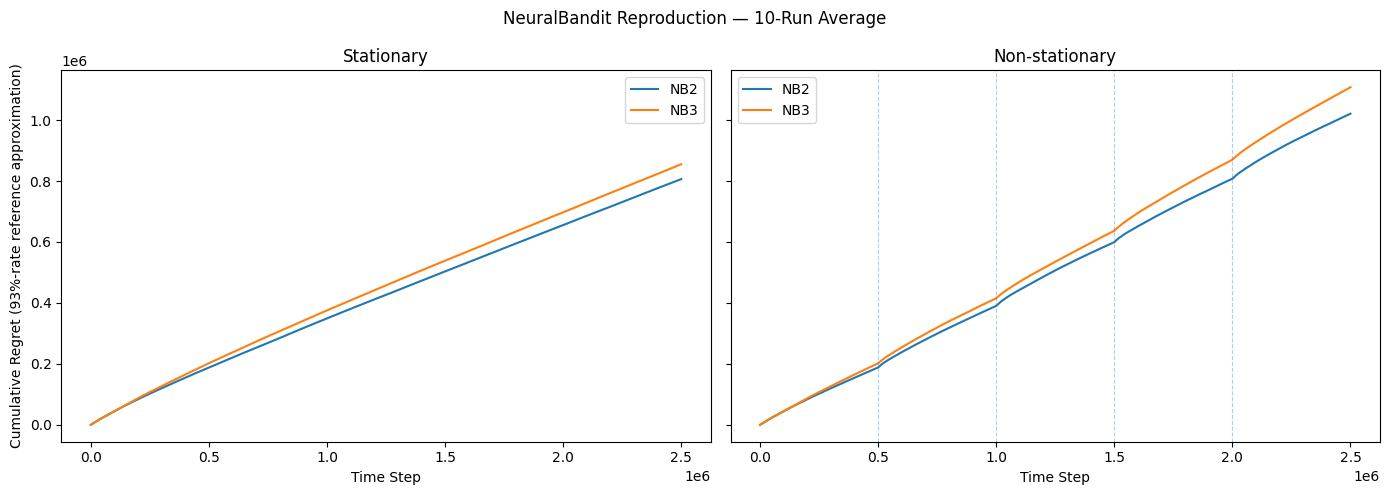

In [ ]:

# ============================================================
# 13A. 93%-rate reference regret approximation
# ============================================================

steps = np.arange(
    1,
    T + 1
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    sharey=True
)

axes[0].plot(
    steps,
    NB2_STATIONARY[
        "rate93_regret_approx"
    ],
    label="NB2"
)

axes[0].plot(
    steps,
    NB3_STATIONARY[
        "rate93_regret_approx"
    ],
    label="NB3"
)

axes[0].set_title(
    "Stationary"
)
axes[0].set_xlabel(
    "Time Step"
)
axes[0].set_ylabel(
    "Cumulative Regret "
    "(93%-rate reference approximation)"
)
axes[0].legend()

axes[1].plot(
    steps,
    NB2_NONSTATIONARY[
        "rate93_regret_approx"
    ],
    label="NB2"
)

axes[1].plot(
    steps,
    NB3_NONSTATIONARY[
        "rate93_regret_approx"
    ],
    label="NB3"
)

for drift_step in range(
    DRIFT_INTERVAL,
    T,
    DRIFT_INTERVAL
):
    axes[1].axvline(
        drift_step,
        linestyle="--",
        linewidth=0.8,
        alpha=0.35
    )

axes[1].set_title(
    "Non-stationary"
)
axes[1].set_xlabel(
    "Time Step"
)
axes[1].legend()

plt.suptitle(
    "NeuralBandit Reproduction — "
    "10-Run Average"
)
plt.tight_layout()
plt.show()


/tmp/ipykernel_1822/321530272.py:75: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


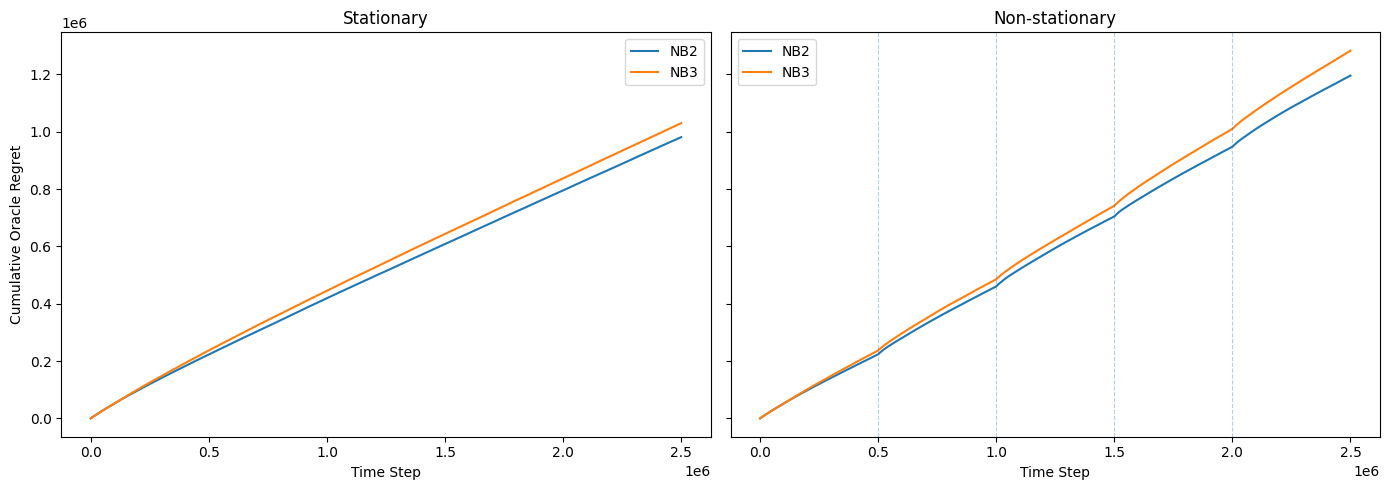

In [ ]:

# ============================================================
# 13B. Exact oracle regret
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    sharey=True
)

axes[0].plot(
    steps,
    NB2_STATIONARY[
        "oracle_regret"
    ],
    label="NB2"
)

axes[0].plot(
    steps,
    NB3_STATIONARY[
        "oracle_regret"
    ],
    label="NB3"
)

axes[0].set_title(
    "Stationary"
)
axes[0].set_xlabel(
    "Time Step"
)
axes[0].set_ylabel(
    "Cumulative Oracle Regret"
)
axes[0].legend()

axes[1].plot(
    steps,
    NB2_NONSTATIONARY[
        "oracle_regret"
    ],
    label="NB2"
)

axes[1].plot(
    steps,
    NB3_NONSTATIONARY[
        "oracle_regret"
    ],
    label="NB3"
)

for drift_step in range(
    DRIFT_INTERVAL,
    T,
    DRIFT_INTERVAL
):
    axes[1].axvline(
        drift_step,
        linestyle="--",
        linewidth=0.8,
        alpha=0.35
    )

axes[1].set_title(
    "Non-stationary"
)
axes[1].set_xlabel(
    "Time Step"
)
axes[1].legend()

plt.tight_layout()
plt.show()


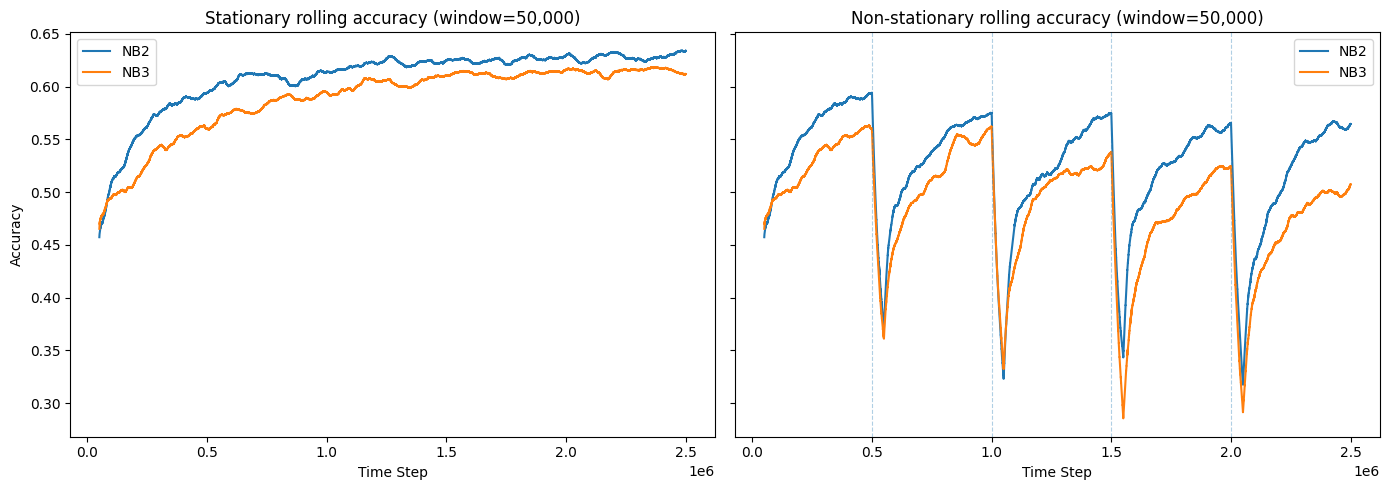

In [ ]:

# ============================================================
# 13C. Rolling accuracy
# ============================================================

WINDOW = 50_000

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    sharey=True
)

for label, result in [
    ("NB2", NB2_STATIONARY),
    ("NB3", NB3_STATIONARY)
]:
    roll = rolling_mean(
        result["mean_reward"],
        WINDOW
    )

    axes[0].plot(
        np.arange(
            WINDOW,
            T + 1
        ),
        roll,
        label=label
    )

axes[0].set_title(
    f"Stationary rolling accuracy "
    f"(window={WINDOW:,})"
)
axes[0].set_xlabel(
    "Time Step"
)
axes[0].set_ylabel(
    "Accuracy"
)
axes[0].legend()

for label, result in [
    ("NB2", NB2_NONSTATIONARY),
    ("NB3", NB3_NONSTATIONARY)
]:
    roll = rolling_mean(
        result["mean_reward"],
        WINDOW
    )

    axes[1].plot(
        np.arange(
            WINDOW,
            T + 1
        ),
        roll,
        label=label
    )

for drift_step in range(
    DRIFT_INTERVAL,
    T,
    DRIFT_INTERVAL
):
    axes[1].axvline(
        drift_step,
        linestyle="--",
        linewidth=0.8,
        alpha=0.35
    )

axes[1].set_title(
    f"Non-stationary rolling accuracy "
    f"(window={WINDOW:,})"
)
axes[1].set_xlabel(
    "Time Step"
)
axes[1].legend()

plt.tight_layout()
plt.show()


## 14. Save experiment metadata

In [ ]:

# ============================================================
# 14. Save experiment metadata
# ============================================================

metadata = {
    "paper": (
        "A Neural Networks Committee "
        "for the Contextual Bandit Problem"
    ),
    "T": T,
    "T_source": (
        "approximately inferred "
        "from Figure 1"
    ),
    "n_runs": N_RUNS,
    "gamma": float(GAMMA),
    "gamma_model":
        float(GAMMA_MODEL),
    "drift_interval":
        DRIFT_INTERVAL,
    "last_n":
        LAST_N,
    "offline_reference_accuracy":
        float(
            OFFLINE_REFERENCE_ACCURACY
        ),
    "hidden_sizes":
        HIDDEN_SIZES.tolist(),
    "learning_rates":
        LEARNING_RATES.tolist(),
    "run_starts":
        RUN_STARTS.tolist(),
    "run_seeds":
        RUN_SEEDS.tolist(),
    "data_seed":
        DATA_SEED,
    "experiment_seed":
        EXPERIMENT_SEED,
    "jax_version":
        jax.__version__,
    "devices":
        [str(d) for d in jax.devices()],
    "regret_note": (
        "Exact paper regret cannot be reconstructed "
        "because the 93%-accurate offline classifier "
        "and its per-round reward sequence are unspecified."
    )
}

with open(
    RESULT_DIR / "metadata.json",
    "w"
) as f:
    json.dump(
        metadata,
        f,
        indent=2
    )

print(
    "Saved metadata to:",
    RESULT_DIR / "metadata.json"
)


Saved metadata to: /content/neural_bandit_jax_results/metadata.json
